In [1]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import keras.src.datasets.cifar10 as cifar10
from sklearn.model_selection import train_test_split

In [2]:
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        logical_gpus = tf.config.list_logical_devices('GPU')
        print(len(gpus), "Physical GPUs,", len(logical_gpus), "Logical GPUs")
    except RuntimeError as e:
        print(e)

1 Physical GPUs, 1 Logical GPUs


In [3]:
def plot_learning_curve(history):
    # Graficar exactitud
    plt.figure()
    plt.plot(history.history['accuracy'], label='Training accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation accuracy')
    plt.title('accuracy Curves')
    plt.legend()
    plt.show()

    # Graficar pérdida
    plt.figure()
    plt.plot(history.history['loss'], label='Training Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title('Loss Curves')
    plt.legend()
    plt.show()


In [4]:
MIRROR_CIFAR10 = "https://storage.googleapis.com/tensorflow/tf-keras-datasets/cifar-10-python.tar.gz"

try:
    import keras.src.datasets.cifar10 as cifar10
except ImportError:
    import keras.datasets.cifar10 as cifar10

_get_file = cifar10.get_file

def _get_file_mirror(*args, **kwargs):
    kwargs["origin"] = MIRROR_CIFAR10
    return _get_file(*args, **kwargs)

cifar10.get_file = _get_file_mirror
(x_train, y_train), (x_test, y_test) = cifar10.load_data()
cifar10.get_file = _get_file

y_train = y_train.reshape(-1)
y_test = y_test.reshape(-1)

In [5]:
x_train.shape, x_test.shape

((50000, 32, 32, 3), (10000, 32, 32, 3))

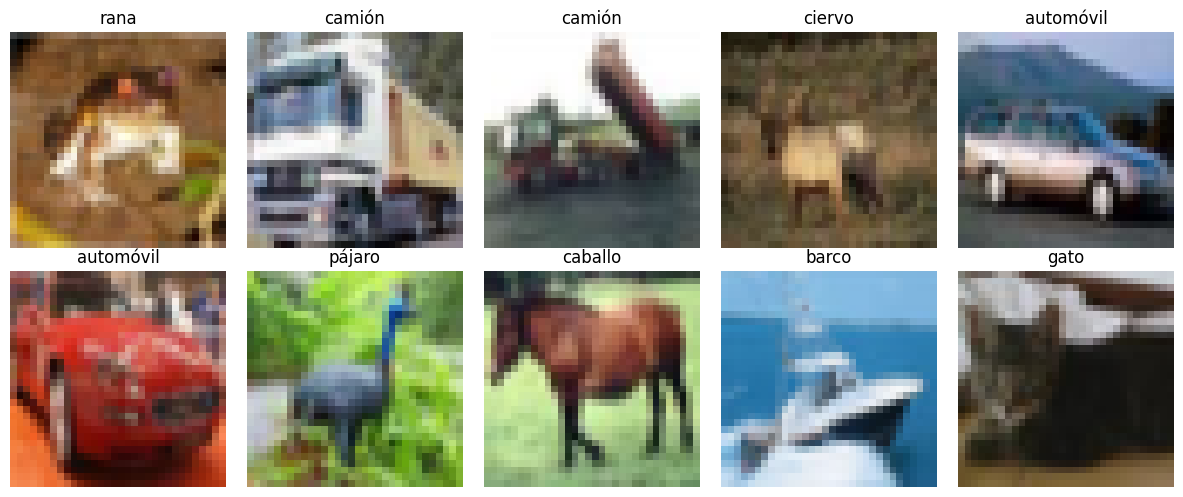

In [6]:
class_names = ["avión", "automóvil", "pájaro", "gato", "ciervo",
               "perro", "rana", "caballo", "barco", "camión"]

plt.figure(figsize=(12, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i])
    plt.title(class_names[y_train[i]])
    plt.axis("off")
plt.tight_layout()
plt.show()

In [7]:
# Separar conjunto de datos
x_test, x_val, y_test, y_val= train_test_split(
    x_test, y_test, test_size=0.50, random_state=42
)

In [8]:
x_train_mlp = x_train / 255.0
x_test_mlp = x_test / 255.0
x_val_mlp = x_val / 255.0

In [9]:
x_train_mlp.shape

(50000, 32, 32, 3)

In [10]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(x_train_mlp.shape[1], x_train_mlp.shape[2], x_train_mlp.shape[3])),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(units = 128, activation = "relu"),
    tf.keras.layers.Dense(units = 64, activation = "relu"),
    tf.keras.layers.Dense(units = 10, activation = "softmax")
])


model.compile(
    optimizer = "adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history = model.fit(
    x_train_mlp,
    y_train,
    epochs = 20,
    batch_size = 32,
    validation_data = (x_val_mlp, y_val)
)

Epoch 1/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.3267 - loss: 1.8712 - val_accuracy: 0.3758 - val_loss: 1.7252
Epoch 2/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.3880 - loss: 1.7053 - val_accuracy: 0.4098 - val_loss: 1.6600
Epoch 3/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.4138 - loss: 1.6363 - val_accuracy: 0.4258 - val_loss: 1.5978
Epoch 4/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.4266 - loss: 1.5930 - val_accuracy: 0.4274 - val_loss: 1.6099
Epoch 5/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.4451 - loss: 1.5551 - val_accuracy: 0.4398 - val_loss: 1.5873
Epoch 6/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.4542 - loss: 1.5293 - val_accuracy: 0.4408 - val_loss: 1.5680
Epoch 7/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.4617 - loss: 1.5067 - val_accuracy: 0.4654 - val_loss: 1.5265
Epoch 8/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.4677 - loss: 1.4883 -

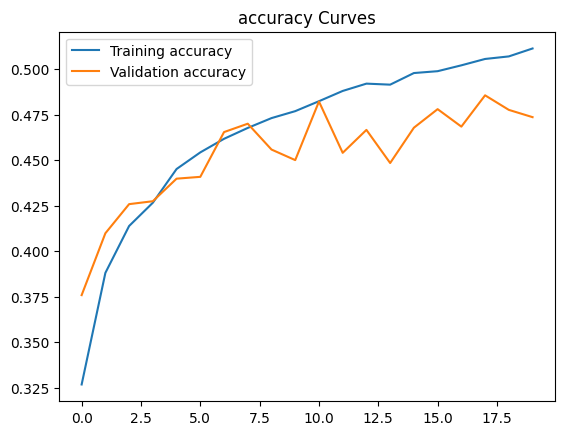

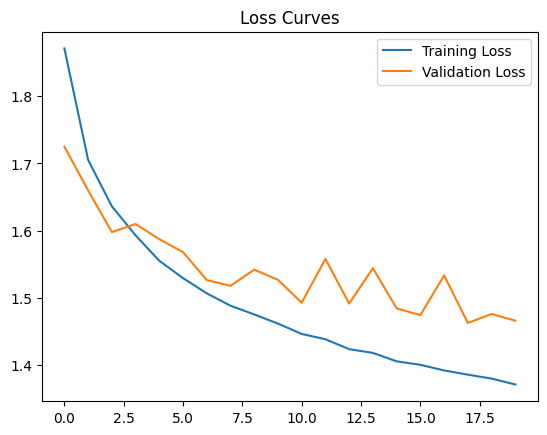

In [11]:
plot_learning_curve(history)

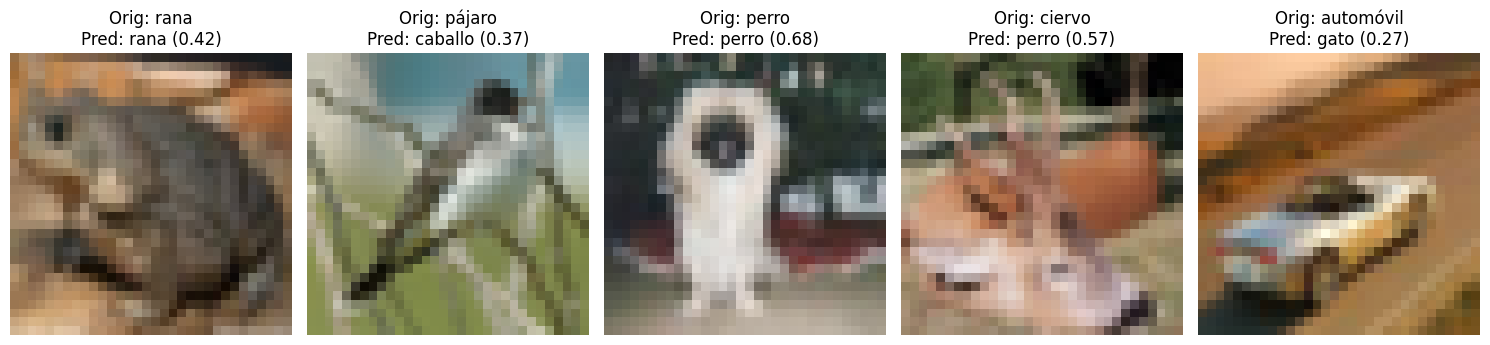

In [12]:
# Seleccionar 5 imágenes de prueba
num_images = 5
original_images = x_test_mlp[num_images:num_images+5]
original_labels = y_test[num_images:num_images+5]

# Realizar predicciones para originales y desplazadas
preds_original = model.predict(original_images, verbose=0)

# Graficar los resultados de la comparación
fig, axes = plt.subplots(1, num_images, figsize=(15, 6))

for i in range(num_images):
    # Mostrar imagen original
    axes[i].imshow(original_images[i])
    pred_orig_label = np.argmax(preds_original[i])
    pred_orig_conf = preds_original[i][pred_orig_label]
    axes[i].set_title(f"Orig: {class_names[original_labels[i]]}\nPred: {class_names[pred_orig_label]} ({pred_orig_conf:.2f})")
    axes[i].axis('off')

plt.tight_layout()
plt.show()

In [13]:
# Imagen en el índice 8 (Un ciervo con 57%)
model.predict(x_test_mlp[8].reshape(1,32,32,3), verbose=0)

array([[0.00163765, 0.00394417, 0.01633252, 0.24677573, 0.03958165,
        0.57022977, 0.04800268, 0.05715942, 0.00115994, 0.01517649]],
      dtype=float32)

In [23]:
class_names[5], class_names[3], class_names[7],

('perro', 'gato', 'caballo')

Epoch 1/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 18s 8ms/step - accuracy: 0.4962 - loss: 1.3973 - val_accuracy: 0.6252 - val_loss: 1.0486
Epoch 2/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.6664 - loss: 0.9547 - val_accuracy: 0.6990 - val_loss: 0.8911
Epoch 3/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.7209 - loss: 0.7991 - val_accuracy: 0.7212 - val_loss: 0.8180
Epoch 4/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.7569 - loss: 0.6993 - val_accuracy: 0.7296 - val_loss: 0.7911
Epoch 5/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.7869 - loss: 0.6138 - val_accuracy: 0.7252 - val_loss: 0.8060
Epoch 6/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8088 - loss: 0.5483 - val_accuracy: 0.7242 - val_loss: 0.8407
Epoch 7/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8283 - loss: 0.4913 - val_accuracy: 0.7402 - val_loss: 0.8299
Epoch 8/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8459 - loss: 0.4387 -

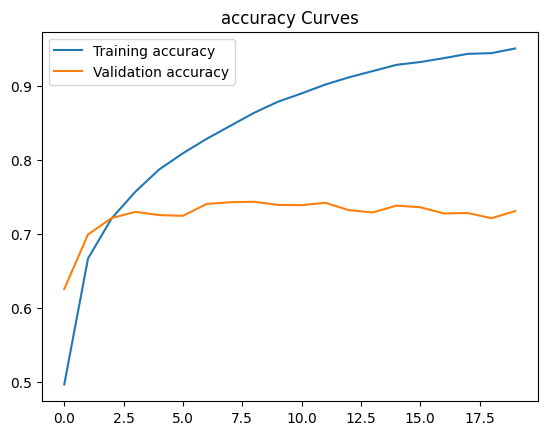

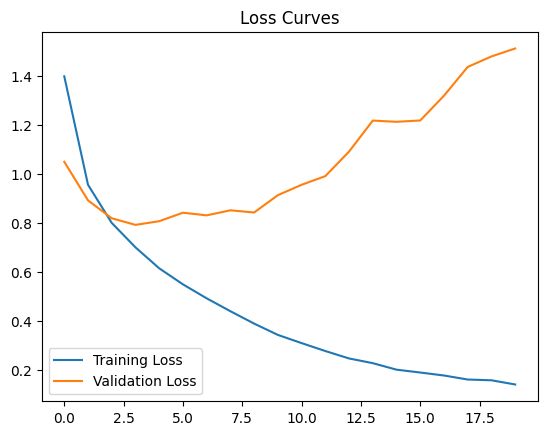

In [15]:
model_conv = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(x_train_mlp.shape[1], x_train_mlp.shape[2], x_train_mlp.shape[3])),

    tf.keras.layers.Conv2D(32, (3, 3), padding = "same", activation = "relu"),
    tf.keras.layers.MaxPool2D((2, 2)),

    tf.keras.layers.Conv2D(64, (3, 3), padding = "same", activation = "relu"),
    tf.keras.layers.MaxPool2D((2, 2)),

    tf.keras.layers.Conv2D(128, (3, 3), padding = "same", activation = "relu"),
    tf.keras.layers.MaxPool2D((2, 2)),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(units = 64, activation = "relu"),
    tf.keras.layers.Dense(units = 10, activation = "softmax")
])


model_conv.compile(
    optimizer = "adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history = model_conv.fit(
    x_train_mlp,
    y_train,
    epochs = 20,
    batch_size = 32,
    validation_data = (x_val_mlp, y_val)
)

plot_learning_curve(history)

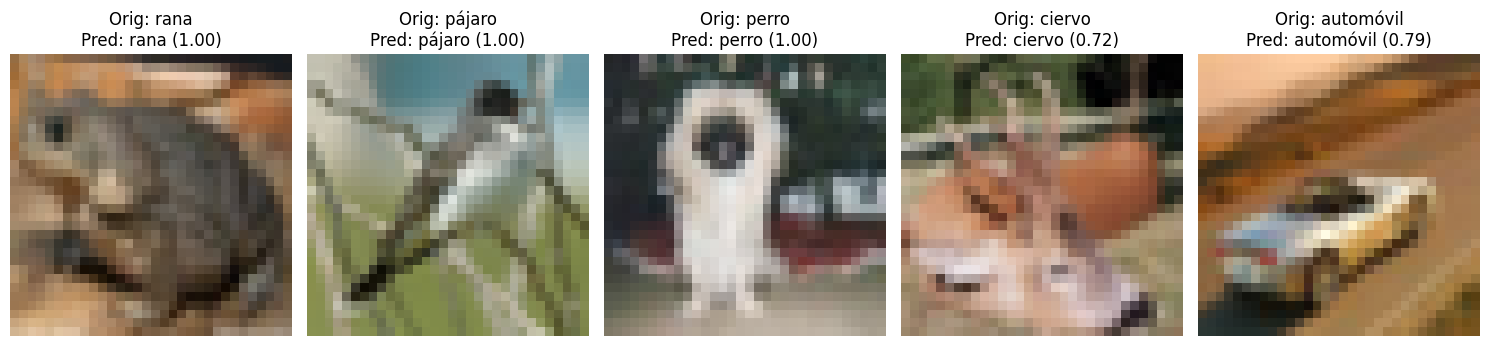

In [16]:
# Seleccionar 5 imágenes de prueba
num_images = 5
original_images = x_test_mlp[num_images:num_images + 5]
original_labels = y_test[num_images:num_images + 5]

# Realizar predicciones para originales y desplazadas
preds_original = model_conv.predict(original_images, verbose=0)

# Graficar los resultados de la comparación
fig, axes = plt.subplots(1, num_images, figsize=(15, 6))

for i in range(num_images):
    # Mostrar imagen original
    axes[i].imshow(original_images[i])
    pred_orig_label = np.argmax(preds_original[i])
    pred_orig_conf = preds_original[i][pred_orig_label]
    axes[i].set_title(f"Orig: {class_names[original_labels[i]]}\nPred: {class_names[pred_orig_label]} ({pred_orig_conf:.2f})")
    axes[i].axis('off')

plt.tight_layout()
plt.show()

In [17]:
# Imagen en el índice 8 (Un ciervo con 72%)
[*map(lambda x: round(float(x),2), model_conv.predict(x_test_mlp[8].reshape(1,32,32,3), verbose=0)[0])]

[0.0, 0.0, 0.0, 0.19, 0.72, 0.0, 0.08, 0.0, 0.0, 0.0]

In [24]:
class_names[4], class_names[3], class_names[6]

('ciervo', 'gato', 'rana')

In [25]:
print(f"Parámetros ANN: {model.count_params():,}")
print(f"Parámetros CNN: {model_conv.count_params():,}")
print(f"La CNN usa {model.count_params() / model_conv.count_params():.1f}× menos parámetros")

Parámetros ANN: 402,250
Parámetros CNN: 225,034
La CNN usa 1.8× menos parámetros


In [20]:
def desplazar(imagenes, pixeles):
    if pixeles == 0:
        return imagenes
    salida = np.zeros_like(imagenes)
    salida[:, :, pixeles:] = imagenes[:, :, :-pixeles]
    return salida

In [21]:
shifts = [0, 2, 4, 8, 12, 16]
acc_ann, acc_cnn = [], []

for s in shifts:
    _, a = model.evaluate(desplazar(x_test_mlp, s), y_test, verbose=0)
    _, c = model_conv.evaluate(desplazar(x_test_mlp, s), y_test, verbose=0)
    acc_ann.append(a)
    acc_cnn.append(c)
    print(f"{s:2d} px -> ANN: {a:.2%} | CNN: {c:.2%}")

 0 px -> ANN: 47.78% | CNN: 72.86%
 2 px -> ANN: 40.28% | CNN: 66.94%
 4 px -> ANN: 28.96% | CNN: 60.38%
 8 px -> ANN: 18.56% | CNN: 38.46%
12 px -> ANN: 14.00% | CNN: 28.46%
16 px -> ANN: 14.26% | CNN: 21.12%


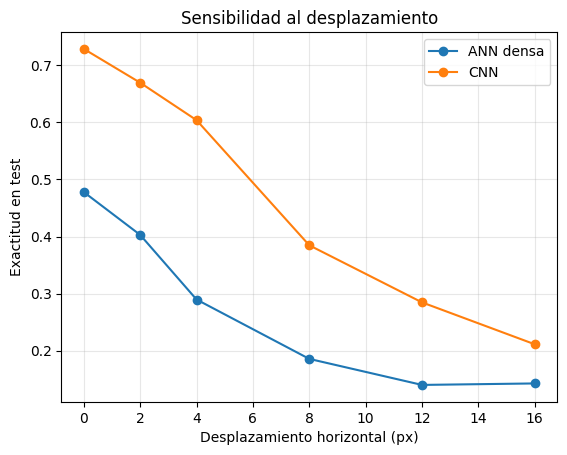

In [22]:
plt.figure()
plt.plot(shifts, acc_ann, marker="o", label="ANN densa")
plt.plot(shifts, acc_cnn, marker="o", label="CNN")
plt.xlabel("Desplazamiento horizontal (px)")
plt.ylabel("Exactitud en test")
plt.title("Sensibilidad al desplazamiento")
plt.legend()
plt.grid(alpha=0.3)
plt.show()